In [35]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Task 1: Loading and Inspecting the Data

We will be working with a dataset of audiobooks downloaded from audible.in from 1998 to 2025 (pre-planned releases). [Source](https://www.kaggle.com/datasets/snehangsude/audible-dataset)

The first thing we will do is load the raw audible data.

### Instructions:
* Using pandas, read the `audible_raw.csv` file that is located inside the `data` folder in our local directory. Assign to `audible`.
* Show the first few rows of the `audible` data frame.

In [36]:
# Load the audible_raw.csv file
audible = pd.read_csv('data/audible_raw.csv')
# View the first rows of the dataframe
audible.head(1)

,name,author,narrator,time,releasedate,language,stars,price
0,Geronimo Stilton #11 & #12,Writtenby:GeronimoStilton,Narratedby:BillLobely,2 hrs and 20 mins,04-08-08,English,5 out of 5 stars34 ratings,468.00


### 💾 The data

- "name" - The name of the audiobook.
- "author" - The audiobook's author.
- "narrator" - The audiobook's narrator.
- "time" -  The audiobook's duration, in hours and minutes.
- "releasedate" -  The date the audiobook was published.
- "language" -  The audiobook's language.
- "stars" -  The average number of stars (out of 5) and the number of ratings (if available).
- "price" -  The audiobook's price in INR (Indian Rupee).

 We can use the `.info()` method to inspect the data types of the columns

In [37]:
# Inspect the columns' data types
audible.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87489 entries, 0 to 87488
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   name         87489 non-null  object
 1   author       87489 non-null  object
 2   narrator     87489 non-null  object
 3   time         87489 non-null  object
 4   releasedate  87489 non-null  object
 5   language     87489 non-null  object
 6   stars        87489 non-null  object
 7   price        87489 non-null  object
dtypes: object(8)
memory usage: 5.3+ MB


## Task 2: Clean text data in Author and Narrator columns

We will start cleaning some of the text columns like `author` and `narrator`. We can remove the `Writtenby:` and `Narratedby:` portions of the text in those columns.

For this, we will use the `.str.replace()` method

### Instructions:
* Remove 'Writtenby:' from the `author` column
* Remove 'Narratedby:' from the `narrator` column
* Check the results

In [38]:
# Remove Writtenby: from the author column
audible['author'] = audible['author'].str.replace('Writtenby:', '')
# Remove Narratedby: from the narrator column
audible['narrator'] = audible['narrator'].str.replace('Narratedby:', '')
# Check the results
print(audible[['author', 'narrator']])

                author        narrator
0      GeronimoStilton      BillLobely
1          RickRiordan   RobbieDaymond
2           JeffKinney      DanRussell
3          RickRiordan  SoneelaNankani
4          RickRiordan  JesseBernstein
...                ...             ...
87484     ChrisStewart    ChrisStewart
87485    StephenO'Shea      RobertFass
87486        MarkTwain       FloGibson
87487   LaurenceSterne     AntonLesser
87488    MarkKurlansky     FleetCooper

[87489 rows x 2 columns]


## Task 3: Extract number of stars and ratings from Stars column.

The `stars` column combines the number of stars and the number of ratins. Let's turn this into numbers and split it into two columns: `rating_stars` and `n_ratings`.

First we will use the `.sample()` method to get a glimpse at the type of entries in that column.

In [39]:
# Get a glimpse of the stars column
audible.stars.sample(n=10)

35000               Not rated yet
33360    3 out of 5 stars1 rating
79468               Not rated yet
40624               Not rated yet
48511               Not rated yet
79992               Not rated yet
37570               Not rated yet
3478                Not rated yet
37864               Not rated yet
82836               Not rated yet
Name: stars, dtype: object

Since there are many instances of `Not rated yet`, let's filter them out and sample again:

In [40]:
# Explore the values of the star column that are not 'Not rated yet'
audible[audible.stars != 'Not rated yet'].stars.sample(n=10)

49888    4.5 out of 5 stars22 ratings
30308        5 out of 5 stars1 rating
61981        3 out of 5 stars1 rating
871         4 out of 5 stars4 ratings
10031        5 out of 5 stars1 rating
76445        3 out of 5 stars1 rating
64329        5 out of 5 stars1 rating
71434     4.5 out of 5 stars6 ratings
55211     3.5 out of 5 stars2 ratings
31254        4 out of 5 stars1 rating
Name: stars, dtype: object

As a first step, we can replace the instances of `Not rated yet` with `NaN`

In [41]:
# Replace 'Not rated yet' with NaN
audible['stars'].replace('Not rated yet', np.nan, inplace=True)
print(audible[audible.stars.isna()].stars.sample(n=5))

81462    NaN
1132     NaN
47060    NaN
61515    NaN
4652     NaN
Name: stars, dtype: object


We can use `.str.extract()` to get the number of stars and the number of ratings into their own columns.

### Instructions:
* Extract the number of stars into the `rating_stars` column
* Extract the number of ratings into the `n_ratings` column
* Convert both new columns to float

In [42]:
# Extract number of stars into rating_stars and turn into float
audible['rating_stars'] = audible['stars'].str.extract('^([\d.]+)').astype(float)
# # Replace the comma, extract number of ratings into n_ratings and turn into float
audible['n_ratings'] = audible['stars'].str.replace(',', '').str.extract('(\d.) ratings').astype(float)
# # Examine the new rating_stars and n_ratings columns
audible[['rating_stars', 'n_ratings']].sample(n=5)

,rating_stars,n_ratings
1154,NaN,NaN
3968,NaN,NaN
71201,NaN,NaN
31610,NaN,NaN
56842,NaN,NaN


In [43]:
print(audible[audible['rating_stars'].isna()]['rating_stars'])

34      NaN
50      NaN
51      NaN
61      NaN
62      NaN
         ..
87484   NaN
87485   NaN
87486   NaN
87487   NaN
87488   NaN
Name: rating_stars, Length: 72417, dtype: float64


As a last step, let's delete the `stars` column using the `.drop` command:

In [44]:
# Drop the stars column
audible = audible.drop(columns=['stars'])
# Check the results
audible.head()

,name,author,narrator,time,releasedate,language,price,rating_stars,n_ratings
0,Geronimo Stilton #11 & #12,GeronimoStilton,BillLobely,2 hrs and 20 mins,04-08-08,English,468.00,5.0,34.0
1,The Burning Maze,RickRiordan,RobbieDaymond,13 hrs and 8 mins,01-05-18,English,820.00,4.5,41.0
2,The Deep End,JeffKinney,DanRussell,2 hrs and 3 mins,06-11-20,English,410.00,4.5,38.0
3,Daughter of the Deep,RickRiordan,SoneelaNankani,11 hrs and 16 mins,05-10-21,English,615.00,4.5,12.0
4,"The Lightning Thief: Percy Jackson, Book 1",RickRiordan,JesseBernstein,10 hrs,13-01-10,English,820.00,4.5,81.0


## Task 4: Change data types

Another important step is to have our data in the correct data types

### Instructions:
* Set `price` to float
* Turn `rating_stars` to category
* Convert `releasedate` to datetime

In [45]:
# Explore the price column
audible.price.sample(n=10)

5484     139.00
12767    653.00
42015    608.00
55991    293.00
39354    537.00
155       38.00
59130    586.00
66015    586.00
81298     46.00
81820    937.00
Name: price, dtype: object

We need to get rid of the comma and the word 'Free' before we can convert the data.

In [46]:
# Replace the comma with ''
audible.price = audible.price.str.replace(',', '')
# Replace 'Free' with 0
audible.price = audible.price.str.replace('Free', '0')
# Turn price to float
audible.price = audible.price.astype(float)

* Turn `rating_stars` to category

Since `stars` can only take a small number of discrete values, the best data type for the column is `category`.

Let's first look at the unique values in that column to confirm:

In [47]:
# Look at the unique values in the rating_stars column
audible['rating_stars'].unique()

array([5. , 4.5, 4. , nan, 3.5, 3. , 1. , 2. , 2.5, 1.5])

We can now use `.astype` to change the data type.

In [48]:
# Turn rating_stars to category
audible['rating_stars'] = audible['rating_stars'].astype('category')

In [49]:
audible.dtypes

name              object
author            object
narrator          object
time              object
releasedate       object
language          object
price            float64
rating_stars    category
n_ratings        float64
dtype: object

* Convert `releasedate` date to datetime

Here we will use the `to_datetime()` function to turn the dates into datetime objects:

In [50]:
# Convert releasedate to datetime
audible.releasedate = pd.to_datetime(audible.releasedate)
# Inspect the dataframe 
audible.releasedate.sample(n=10)

29729   2021-11-16
73461   2022-09-02
78195   2017-03-03
50333   2022-03-02
29646   2021-09-11
50736   2021-07-09
64758   2021-09-11
41739   2014-01-24
86494   2014-01-04
66266   2021-06-30
Name: releasedate, dtype: datetime64[ns]

## Task 5: Extract hours and minutes from the `time` column

The `time` column combines the number of hours and minutes into one column. We want to transform and consolidate the information into a new `time_minutes` column.

In [51]:
# Explore the values in the time column
audible.time.sample(n=10)

22447    12 hrs and 39 mins
3135                 2 mins
23882     4 hrs and 40 mins
72629     2 hrs and 33 mins
37424     8 hrs and 38 mins
48409      8 hrs and 3 mins
76886     8 hrs and 26 mins
42308     4 hrs and 41 mins
59679    13 hrs and 18 mins
2209       1 hr and 31 mins
Name: time, dtype: object

Let's see what other ways they have encoded `min` or `minutes`:

In [52]:
# Search the entries in the time column for different spellings of min. Let' try min, mins, minutes
audible[audible.time.str.contains('min')].time

0         2 hrs and 20 mins
1         13 hrs and 8 mins
2          2 hrs and 3 mins
3        11 hrs and 16 mins
5        10 hrs and 35 mins
                ...        
87484     7 hrs and 34 mins
87485     10 hrs and 7 mins
87486     19 hrs and 4 mins
87487      4 hrs and 8 mins
87488       6 hrs and 1 min
Name: time, Length: 86146, dtype: object

We can see that we need to fix the following:
* hr, hrs -> consolidate as `hr`
* min, mins -> consolidate as `min`
* Less than 1 minute -> round to 1 min

In [53]:
# Replace hrs, mins, and 'Less than 1 minute'
audible.time = audible.time.str.replace('s', '')
audible.time = audible.time.str.replace('Less than 1 minute', '1 min')

Let's see how it looks now:

In [54]:
# Check the results
audible.time.sample(n=10)

26285     9 hr and 52 min
59152     8 hr and 23 min
79261    27 hr and 23 min
1723               11 min
30152     6 hr and 28 min
16708              13 min
79515     2 hr and 51 min
8044      2 hr and 24 min
54318      7 hr and 8 min
78993    16 hr and 51 min
Name: time, dtype: object

The next step is to extract the number of hours and minutes from the text, then combine in a new `time_mins` column.

### Instructions: 
* Extract the number of hours from `time`. Assign to the `hours` variable.
* Extract the number of minutes from `time`. Assign to the `mins` variable.
* Create the `time_mins` column combining hours and minutes.

In [55]:
# Extract the number of hours, turn to integer
hours = audible.time.str.extract('(\d+) hr').fillna(0).astype(int)
# Extract the number of minutes, turn to integer
minutes = audible.time.str.extract('(\d+) min').fillna(0).astype(int)
# Combine hours and minutes into the time_mins column
audible['time_mins'] = (hours * 60) + minutes
# Check the results
audible['time_mins'].sample(n=10)

51363    889
77008    638
86614     69
2295       2
57485    243
18742    343
49350    121
81703    717
11291    448
49461    661
Name: time_mins, dtype: int64

And as final step, let's delete the columns we don't need any more:

In [56]:
# Drop the time column
audible.drop(columns=['time'], inplace=True)

In [57]:
audible.head()

,name,author,narrator,releasedate,language,price,rating_stars,n_ratings,time_mins
0,Geronimo Stilton #11 & #12,GeronimoStilton,BillLobely,2008-04-08,English,468.0,5.0,34.0,140
1,The Burning Maze,RickRiordan,RobbieDaymond,2018-01-05,English,820.0,4.5,41.0,788
2,The Deep End,JeffKinney,DanRussell,2020-06-11,English,410.0,4.5,38.0,123
3,Daughter of the Deep,RickRiordan,SoneelaNankani,2021-05-10,English,615.0,4.5,12.0,676
4,"The Lightning Thief: Percy Jackson, Book 1",RickRiordan,JesseBernstein,2010-01-13,English,820.0,4.5,81.0,600


Here is how our dataframe looks now:

In [58]:
# Inspect the dataframe 
audible.sample(n=10)

,name,author,narrator,releasedate,language,price,rating_stars,n_ratings,time_mins
80639,Mets by the Numbers,"JonSpringer,MatthewSilverman",JimBarton,2013-02-23,English,668.0,NaN,NaN,555
36801,"Love, Sex, and Science",ScientificAmerican,JanetMetzger,2020-07-07,English,702.0,5.0,NaN,381
6606,Liberty for All?,JoyHakim,ChristinaMoore,2005-04-02,English,668.0,NaN,NaN,341
66906,Flow of Grace,KrishnaDas,KrishnaDas,2022-03-01,English,258.0,NaN,NaN,119
82559,Drag Teen,JefferySelf,JefferySelf,2016-04-26,English,575.0,NaN,NaN,365
30100,The Art of Conversation,JudyApps,ImogenChurch,2020-07-27,English,620.0,NaN,NaN,331
49841,Bewilderment,RichardPowers,EdoardoBallerini,2021-09-21,English,888.0,4.0,12.0,471
67504,The Last Jews in Berlin,LeonardGross,DaviddeVries,2019-06-28,English,703.0,NaN,NaN,639
7214,"Sterne, Schnee und Weihnachtsduft. Meine schön...","JosephvonEichendorff,HansChristianAndersen,The...","ChristianRode,UtaHallant,DieterLanduris",2007-12-11,german,267.0,NaN,NaN,75
10262,Little Tug,StephenSavage,ChristinaDelaine,2013-09-04,English,13.0,NaN,NaN,1


## Task 6: Check data ranges

Another important step is to confirm that the values in our columns are in the expected ranges and that we don't have out-of-range values.

Let's create a histogram of the numeric columns to visually inspect ht ranges and the shape of the distribution:

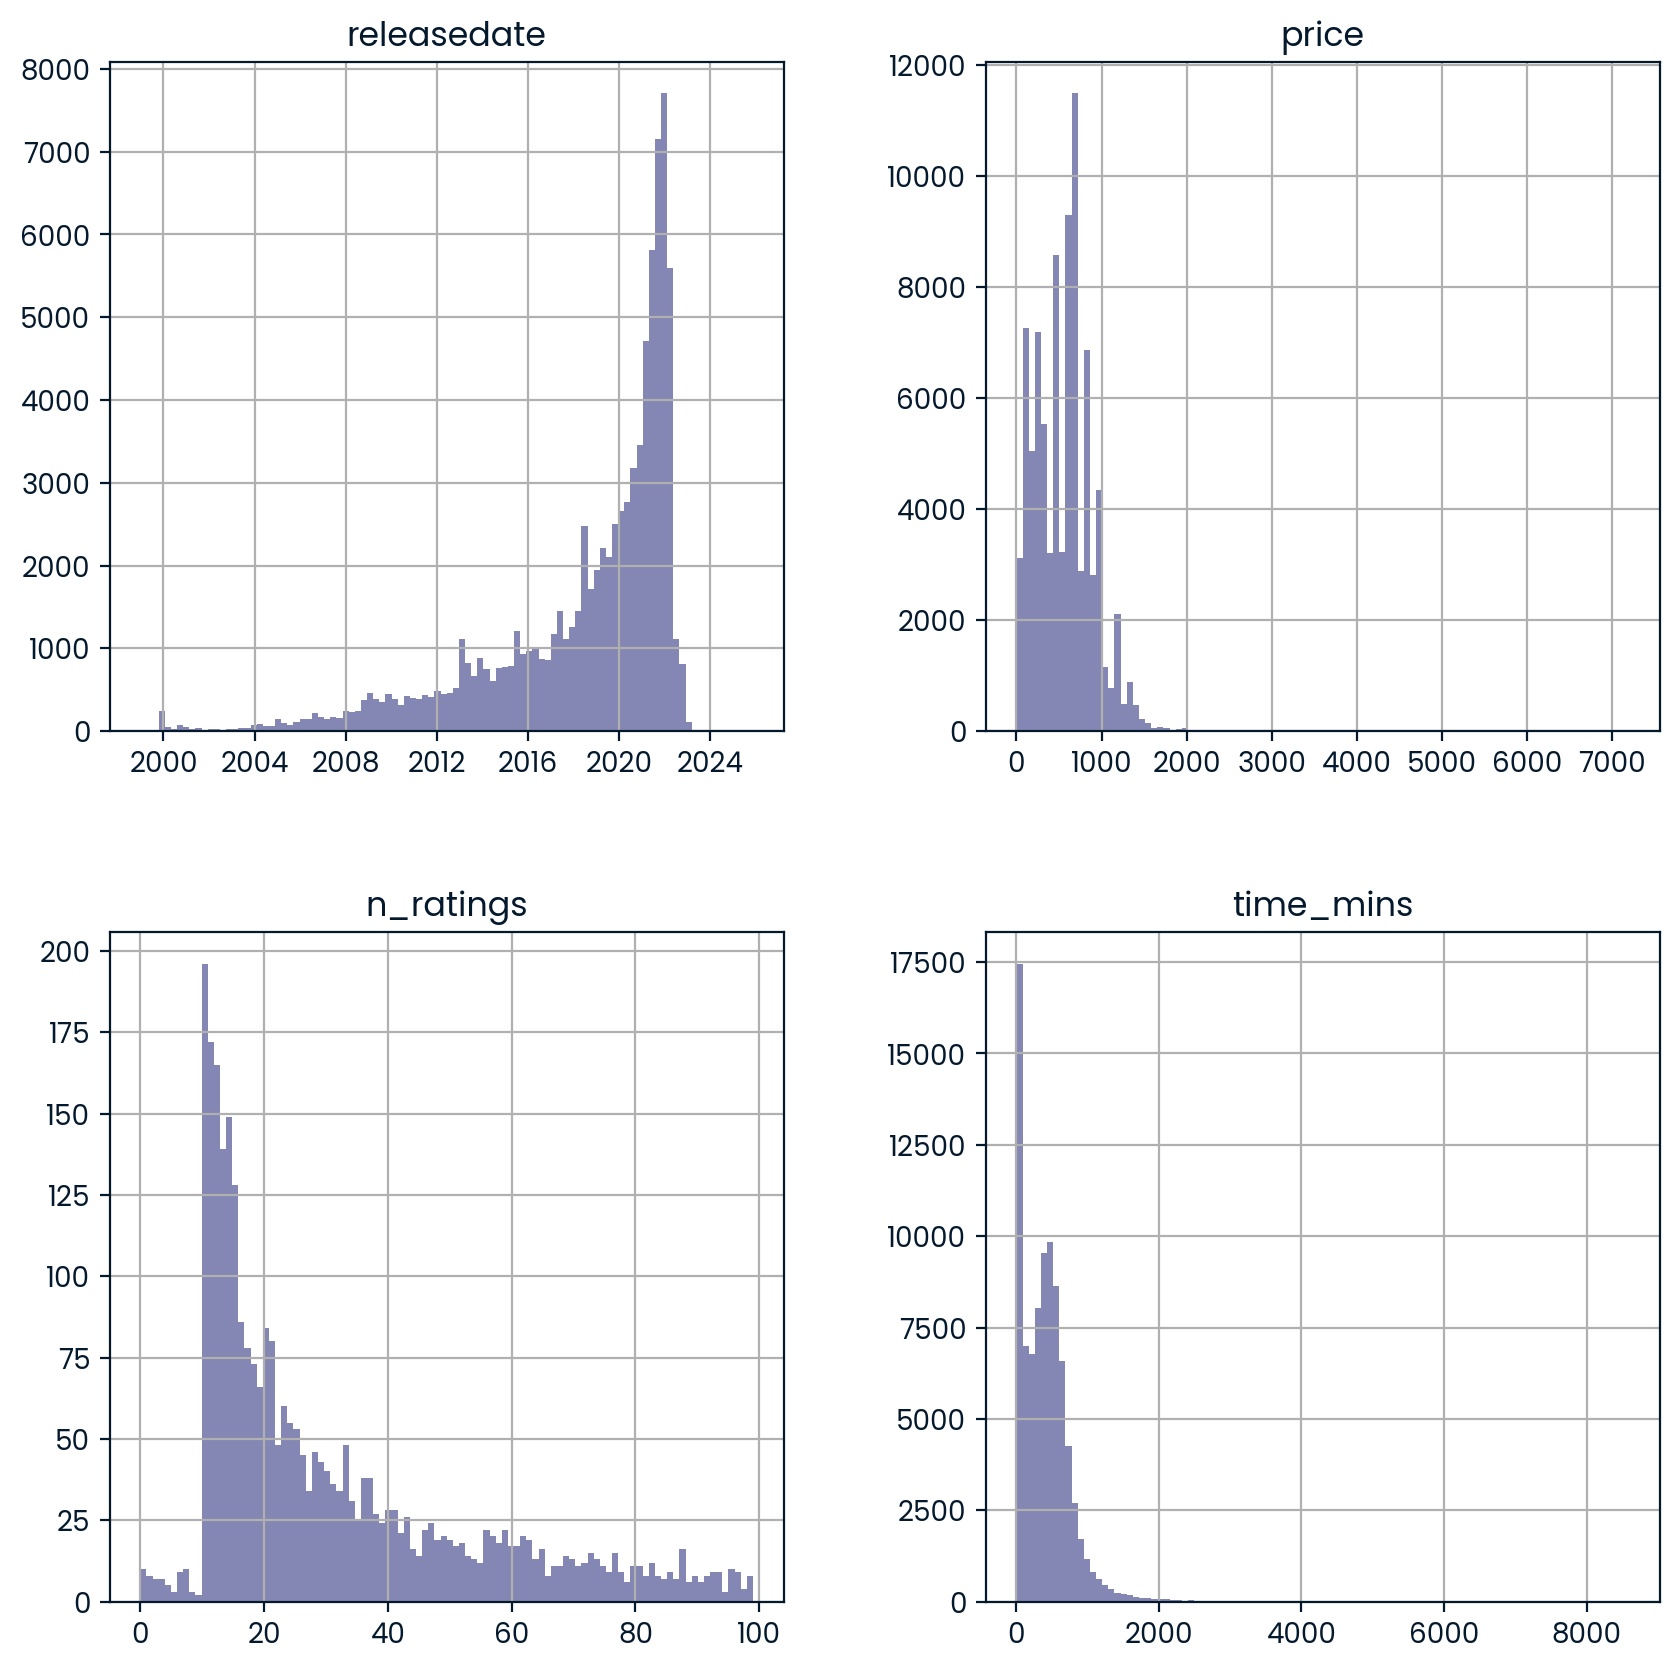

In [59]:
# Plot histograms of all the numerical columns
audible.hist(alpha=0.8, figsize=(10, 10), bins=100)
plt.show()

Additionally, we can use `.describe()` to look at a summary of our data

In [60]:
# Look at the numeric columns
audible.describe()

,price,n_ratings,time_mins
count,87489.000000,3027.000000,87489.000000
mean,559.009246,31.014205,417.497663
std,336.096642,22.715273,364.559399
min,0.000000,0.000000,1.000000
25%,268.000000,14.000000,142.000000
50%,585.000000,22.000000,386.000000
75%,755.000000,42.000000,584.000000
max,7198.000000,99.000000,8595.000000


In [61]:
# Look at the non numeric columns
audible.describe(exclude=[np.number])

,name,author,narrator,releasedate,language,rating_stars
count,87489,87489,87489,87489,87489,15072.0
unique,82767,48374,29717,5058,36,9.0
top,The Art of War,"矢島雅弘,石橋遊",anonymous,2018-05-16 00:00:00,English,5.0
freq,20,874,1034,773,61884,6761.0
first,NaN,NaN,NaN,1998-12-27 00:00:00,NaN,NaN
last,NaN,NaN,NaN,2025-11-14 00:00:00,NaN,NaN


We will transform the prices in `price` to USD for this exercise. We can use the exchange rate of 1 USD = 0.012 INR:

In [62]:
# Transform prices to USD (multiply times 0.012)
audible.price = audible.price * 0.012
# Check the results
audible.price.sample(n=10)

7207      2.796
64974     8.016
79029    15.936
68671     4.920
41291    12.036
2688      1.992
56987     9.840
79417     1.668
34410    11.256
72566     5.616
Name: price, dtype: float64

There values in the `language` column have different capitalization. Let's fix that.

In [63]:
# Inspect the language column before making changes
audible.language.sample(n=10)

13241             English
25585             English
32906              german
37767             English
5028              English
68114             English
45790             English
87373             English
38614    mandarin_chinese
24911             English
Name: language, dtype: object

In [64]:
# Update capitalization in the language column
audible.language = audible.language.str.capitalize()
# Check the results
audible.language.head()

0    English
1    English
2    English
3    English
4    English
Name: language, dtype: object

## Task 7: Checking for duplicates

How many duplicates do we have?

As a first step look for duplicates using `.duplicated()` and `.sum()`:

In [65]:
# Look for duplicate rows
audible.duplicated().sum()

4

In [73]:
audible[audible.duplicated()]

,name,author,narrator,releasedate,language,price,rating_stars,n_ratings,time_mins
62348,Emotional Intelligence,DanielGoleman,DanielGoleman,2000-02-18,English,0.888,5.0,NaN,179
62460,Cracking the Code to a Successful Interview,EvanPellett,GeorgeNewbern,2016-12-13,English,7.020,4.0,NaN,136
64799,Figuring,MariaPopova,NataschaMcElhone,2019-07-02,English,11.388,4.5,NaN,1287
67540,Spirit Babies,WalterMakichen,TimDixon,2021-12-10,English,10.548,5.0,NaN,423


It is useful to look for duplicates only using a subset of the columns that make sense. We will use the following subset of columns:
* name
* author
* narrator
* time_mins
* price

Here we use `.duplicated()` again, but with our subset of columns.

In [66]:
# Create a list of our subset columns and assign to subset_cols
subset = ['name', 'author', 'narrator', 'time_mins', 'price']
# Check for duplicates using our subset of columns
audible[audible.duplicated(subset=subset)]

,name,author,narrator,releasedate,language,price,rating_stars,n_ratings,time_mins
3633,David Karp,KarenLatchanaKenney,Intuitive,2017-01-01,English,1.968,NaN,NaN,27
4326,My First French Lessons,AlexaPolidoro,AlexaPolidoro,2006-12-18,English,2.280,NaN,NaN,59
4329,Ella Earns Her Own Money,LisaBullard,Intuitive,2017-01-01,English,1.968,NaN,NaN,5
8808,Die geheimnisvolle Trommel,GuidoKäpernick,JeskoDoering,2019-01-30,German,3.204,NaN,NaN,94
16971,Adagio in Dm,BillBrown,BillBrown,2021-06-08,English,5.472,NaN,NaN,78
...,...,...,...,...,...,...,...,...,...
79757,Mythos,StephenFry,StephenFry,2017-02-11,English,11.484,4.5,78.0,925
79801,He Who Fights with Monsters 5,"Shirtaloon,TravisDeverell",HeathMiller,2022-05-04,English,24.120,5.0,NaN,1205
80078,Path of Destruction,DrewKarpyshyn,JonathanDavis,2012-10-30,English,14.472,5.0,15.0,736
81940,Biology for 11th Grade [Russian Edition],N.Gavrilova,IlyaGlukhov,2013-03-29,Russian,1.404,NaN,NaN,222


Let's look at those values (use `keep=false`) and see what is going on:

In [67]:
# Check the duplicated rows keeping the duplicates and order by the name column
audible[audible.duplicated(keep=False)]

,name,author,narrator,releasedate,language,price,rating_stars,n_ratings,time_mins
26756,Figuring,MariaPopova,NataschaMcElhone,2019-07-02,English,11.388,4.5,NaN,1287
29465,Cracking the Code to a Successful Interview,EvanPellett,GeorgeNewbern,2016-12-13,English,7.020,4.0,NaN,136
35982,Emotional Intelligence,DanielGoleman,DanielGoleman,2000-02-18,English,0.888,5.0,NaN,179
36742,Spirit Babies,WalterMakichen,TimDixon,2021-12-10,English,10.548,5.0,NaN,423
62348,Emotional Intelligence,DanielGoleman,DanielGoleman,2000-02-18,English,0.888,5.0,NaN,179
62460,Cracking the Code to a Successful Interview,EvanPellett,GeorgeNewbern,2016-12-13,English,7.020,4.0,NaN,136
64799,Figuring,MariaPopova,NataschaMcElhone,2019-07-02,English,11.388,4.5,NaN,1287
67540,Spirit Babies,WalterMakichen,TimDixon,2021-12-10,English,10.548,5.0,NaN,423


We can see that the duplicates are for files with different release dates. We can decide to keep the record with the last release date.

We will can use the `drop_duplicates()` method with the same subset and using `keep=last` to keep the last release date

In [76]:
# Drop duplicated rows keeping the last release date
audible.drop_duplicates(subset=subset, keep='last')

,name,author,narrator,releasedate,language,price,rating_stars,n_ratings,time_mins
0,Geronimo Stilton #11 & #12,GeronimoStilton,BillLobely,2008-04-08,English,5.616,5.0,34.0,140
1,The Burning Maze,RickRiordan,RobbieDaymond,2018-01-05,English,9.840,4.5,41.0,788
2,The Deep End,JeffKinney,DanRussell,2020-06-11,English,4.920,4.5,38.0,123
3,Daughter of the Deep,RickRiordan,SoneelaNankani,2021-05-10,English,7.380,4.5,12.0,676
4,"The Lightning Thief: Percy Jackson, Book 1",RickRiordan,JesseBernstein,2010-01-13,English,9.840,4.5,81.0,600
...,...,...,...,...,...,...,...,...,...
87484,Last Days of the Bus Club,ChrisStewart,ChrisStewart,2017-09-03,English,7.152,NaN,NaN,454
87485,The Alps,StephenO'Shea,RobertFass,2017-02-21,English,9.840,NaN,NaN,607
87486,The Innocents Abroad,MarkTwain,FloGibson,2016-12-30,English,11.256,NaN,NaN,1144
87487,A Sentimental Journey,LaurenceSterne,AntonLesser,2011-02-23,English,8.160,NaN,NaN,248


We can check again for duplicates:

In [77]:
# Check again for duplicates using our subset of columns
audible[audible.duplicated()]

,name,author,narrator,releasedate,language,price,rating_stars,n_ratings,time_mins
62348,Emotional Intelligence,DanielGoleman,DanielGoleman,2000-02-18,English,0.888,5.0,NaN,179
62460,Cracking the Code to a Successful Interview,EvanPellett,GeorgeNewbern,2016-12-13,English,7.020,4.0,NaN,136
64799,Figuring,MariaPopova,NataschaMcElhone,2019-07-02,English,11.388,4.5,NaN,1287
67540,Spirit Babies,WalterMakichen,TimDixon,2021-12-10,English,10.548,5.0,NaN,423


## Task 8: Dealing with missing data

Before we finish, let's take a look at missing data in our columns. We can use the `.isna()` method and chain it with `.sum()` to get the total:

In [78]:
# Check for null values
audible.isna().sum()

name                0
author              0
narrator            0
releasedate         0
language            0
price               0
rating_stars    72417
n_ratings       84462
time_mins           0
dtype: int64

We could turn the **NaN** values to 0 or another numeric value, or we could keep them. It depends on our use case.

If we want to plot the ratings distribution, it can make sense to drop audiobooks with no ratings. But if we need to use the distribution of prices for our analysis, then removing audiobooks with no ratings will bias our results (since unrated audiobooks are likely more niche and might have a different pricing structure than rated audiobooks).

We will keep the unrated audiobooks for now.

## Task 9: Save the cleaned data set

We can use the `.to_csv` method to save the clean file. We include `index=False` so that we don't also copy the current index to our destination file.

In [71]:
# Save the dataframe to a new file: 'audible_clean.csv'
